<a href="https://colab.research.google.com/github/FreddyForero1988/skills-getting-started-with-github-copilot/blob/main/Proyecto_Aplicaciones_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UNIVERSIDAD DE CUNDINAMARCA - ESPECIALIZACIÓN EN INTELIGENCIA ARTIFICIAL #
## Aplicaciones en Deep Learning
## Proyecto: Predicción de confort acústico urbano (Sistema hibrido ASED-WASN)

## Librerias

In [20]:
import os
import urllib.request
import zipfile
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
import librosa.display
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

# Intentar importar MLflow; si no está instalado, se instala automáticamente

try:
  import mlflow
  import mlflow.sklearn
  import mlflow.pytorch
except ImportError:
  print("Instalando MLflow para MLOps Tracking...")
  !pip install mlflow -q
  import mlflow
  import mlflow.sklearn
  import mlflow.pytorch
  print("Dependencias e infraestructura MLOps configuradas correctamente.")


## BLOQUE 1: DESCARGA E INGESTA DEL DATASET PÚBLICO (ESC-50)

In [21]:
print("1-INICIANDO FASE 1: DESCARGA Y CURADURÍA DE DATOS DE AUDIO (ESC-50)...")
DATASET_URL = "https://github.com/karolpiczak/ESC-50/archive/master.zip"
ZIP_PATH = "ESC-50-master.zip"
EXTRACT_DIR = "ESC-50_data"
if not os.path.exists(EXTRACT_DIR):
  print("1-Descargando dataset público de sonidos ambientales ESC-50...")
  urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
  with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)
  print("Descarga y extracción completadas.")
else:
  print("Dataset ESC-50 ya disponible localmente.")

CSV_META = os.path.join(EXTRACT_DIR, "ESC-50-master", "meta", "esc50.csv")
AUDIO_DIR = os.path.join(EXTRACT_DIR, "ESC-50-master", "audio")
df_meta = pd.read_csv(CSV_META)
# Mapeo de categorías ESC-50 a las clases ASED del artículo de referencia
# Clases: Birds, Road_Traffic, Construction, Crowd, Water, Other
ased_mapping = {
    'chirping_birds': 'Birds',
    'cawing_crow': 'Birds',
    'car_horn': 'Road_Traffic',
    'engine': 'Road_Traffic',
    'jackhammer': 'Construction',
    'chainsaw': 'Construction',
    'crowd': 'Crowd',
    'laughing':  'Crowd',
    'water_drops': 'Water',
    'pouring_water': 'Water',
    'sea_waves': 'Water'
}

df_ased = df_meta[df_meta['category'].isin(ased_mapping.keys())].copy()
df_ased['ased_class'] = df_ased['category'].map(ased_mapping)
print(f"Dataset filtrado para ASED: {len(df_ased)} muestras seleccionadas.")
print(df_ased['ased_class'].value_counts())

1-INICIANDO FASE 1: DESCARGA Y CURADURÍA DE DATOS DE AUDIO (ESC-50)...
Dataset ESC-50 ya disponible localmente.
Dataset filtrado para ASED: 320 muestras seleccionadas.
ased_class
Water           120
Road_Traffic     80
Birds            40
Construction     40
Crowd            40
Name: count, dtype: int64


## BLOQUE 2: PREPROCESAMIENTO Y EXTRACCIÓN DE GTCC (GAMMATONE CEPSTRAL COEFFICIENTS)

In [22]:
print("2 - INICIANDO EXTRACTOR DE CARACTERÍSTICAS ACÚSTICAS (GTCC @ 22.05 kHz)...")
TARGET_SR = 22050 # Frecuencia de muestreo estandarizada a 22.05 kHz
DURATION = 5 # Segundos por muestra en ESC-50 (normalizado)

def extract_gtcc_features(file_path, sr=TARGET_SR, n_filters=26, n_ceps=13):
  """ Simulación del Banco de Filtros Gammatone y extracción GTCC usando librosa. """
  y, _ = librosa.load(file_path, sr=sr, duration=DURATION)
  # Espectrograma auditivo simular respuesta biológica auditiva
  S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=n_filters, fmin=20, fmax=sr//2)
  log_S = librosa.power_to_db(S, ref=np.max)
  gtcc = librosa.feature.mfcc(S=log_S, n_mfcc=n_ceps)
  return np.mean(gtcc.T, axis=0)

X_gtcc = []
y_labels = []
label_map = {cls: idx for idx, cls in enumerate(df_ased['ased_class'].unique())}
inv_label_map = {v: k for k, v in label_map.items()}

for idx, row in df_ased.iterrows():
  audio_path = os.path.join(AUDIO_DIR, row['filename'])
  feat = extract_gtcc_features(audio_path)
  X_gtcc.append(feat)
  y_labels.append(label_map[row['ased_class']])

X_gtcc = np.array(X_gtcc)
y_labels = np.array(y_labels)
print(f"Extracción GTCC finalizada. Matriz de características: {X_gtcc.shape}")

2 - INICIANDO EXTRACTOR DE CARACTERÍSTICAS ACÚSTICAS (GTCC @ 22.05 kHz)...
Extracción GTCC finalizada. Matriz de características: (320, 13)


## BLOQUE 3: SIMULACIÓN DE RED WASN Y FILTRADO ESPACIAL HAVERSINE (BARCELONA)

In [23]:
print("3 - GENERANDO DATOS SINTÉTICOS DE LA RED WASN (SENSORES PÚBLICOS)...")

def haversine_distance(lat1, lon1, lat2, lon2):
  R = 6368.833 # Radio de la Tierra en km (Barcelona)
  lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
  dlat = lat2 - lat1
  dlon = lon2 - lon1
  a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
  return 2 * R * np.arcsin(np.sqrt(a))

np.random.seed(42)
n_samples = len(X_gtcc)

# Coordenadas base Barcelona
user_lats = np.random.uniform(41.37, 41.42, n_samples)
user_lons = np.random.uniform(2.13, 2.20, n_samples)

# Generación de sensores WASN
n_sensors = 40
sensor_lats = np.random.uniform(41.37, 41.42, n_sensors)
sensor_lons = np.random.uniform(2.13, 2.20, n_sensors)
area_types = ['heavy-traffic', 'low-traffic', 'leisure', 'park']
sensor_areas = np.random.choice(area_types, n_sensors, p=[0.3, 0.35, 0.28, 0.07])
sensor_laeq = np.where(sensor_areas == 'heavy-traffic', np.random.normal(68, 3, n_sensors), np.where(sensor_areas == 'low-traffic', np.random.normal(58, 4, n_sensors), np.where(sensor_areas == 'leisure', np.random.normal(63, 3, n_sensors), np.random.normal(52, 2, n_sensors))))

# Encontrar sensor más cercano por Haversine <= 1.01 km
wasn_laeq_list = []
wasn_dist_list = []
wasn_area_list = []

for u_lat, u_lon in zip(user_lats, user_lons):
  dists = haversine_distance(u_lat, u_lon, sensor_lats, sensor_lons)
  min_idx = np.argmin(dists)
  min_dist = dists[min_idx]

  # Restricción espacial <= 1.01 km
  if min_dist <= 1.01:
    wasn_laeq_list.append(sensor_laeq[min_idx])
    wasn_dist_list.append(min_dist)
    wasn_area_list.append(sensor_areas[min_idx])
  else:
    # Resiliencia: Asignar promedio histórico zona por defecto
    wasn_laeq_list.append(62.5)
    wasn_dist_list.append(1.01)
    wasn_area_list.append('low-traffic')

  df_wasn = pd.DataFrame({
      'LAeq': wasn_laeq_list,
      'distance_km': wasn_dist_list,
      'area_type': wasn_area_list
  })

  print("Filtrado espacial Haversine completado. Muestras integradas con WASN.")

3 - GENERANDO DATOS SINTÉTICOS DE LA RED WASN (SENSORES PÚBLICOS)...
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Haversine completado. Muestras integradas con WASN.
Filtrado espacial Hav

## BLOQUE 4: ENTRENAMIENTO DEL SUB-MODELO CNN (ASED) Y ENSAMBLE CON ÁRBOL DE DECISIÓN

In [33]:
print("4 - INICIANDO ENTRENAMIENTO DE MODELOS (FASE 2)...")
# 4.1 Entrenamiento de Clasificador ASED (Ponderación de probabilidades)
X_train_g, X_test_g, y_train_g, y_test_g, df_train_w, df_test_w = train_test_split( X_gtcc, y_labels, df_wasn, test_size=0.25, random_state=42 )

# Reiniciar índices para garantizar alineación exacta con las matrices NumPy
df_train_w = df_train_w.reset_index(drop=True)
df_test_w = df_test_w.reset_index(drop=True)

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# Estimador ASED liviano equivalente a la CNN
sed_model = RandomForestClassifier(n_estimators=100, random_state=42)
sed_model.fit(X_train_g, y_train_g)

train_probs = sed_model.predict_proba(X_train_g)
test_probs = sed_model.predict_proba(X_test_g)

# 4.2 Función Ground Truth (Asegura vectores 1D con .flatten())
def generate_ground_truth(df_w, probs, label_mapping):
  binary_list = []
  aci_list = []

  for i in range(len(df_w)):
    row = df_w.iloc[i]
    p_birds = probs[i, label_mapping['Birds']] if 'Birds' in label_mapping else 0.0
    p_traffic = probs[i, label_mapping['Road_Traffic']] if 'Road_Traffic' in label_mapping else 0.0
    p_const = probs[i, label_mapping['Construction']] if 'Construction' in label_mapping else 0.0
    laeq = row['LAeq']

    # Puntuación ACI sintética (escala 1 a 5)
    score = 3.0 + (p_birds * 1.5) - (p_traffic * 1.2) - (p_const * 1.5) - ((laeq - 60) / 10.0)
    score_clamped = int(np.clip(np.round(score), 1, 5))
    aci_list.append(score_clamped)
    binary_list.append(1 if score_clamped >= 3 else 0)

  return np.array(binary_list, dtype=int).flatten(), np.array(aci_list, dtype=int).flatten()

# Generar vectores unidimensionales exactos
y_train_bin, y_train_aci = generate_ground_truth(df_train_w, train_probs, label_map)
y_test_bin, y_test_aci = generate_ground_truth(df_test_w, test_probs, label_map)

# 4.3 Matriz de fusión para el Árbol de Decisión Integrador
X_train_fusion = np.hstack([train_probs, df_train_w[['LAeq', 'distance_km']].values])
X_test_fusion = np.hstack([test_probs, df_test_w[['LAeq', 'distance_km']].values])

print(f"Verificación de dimensiones:")
print(f" - Matriz X_train_fusion: {X_train_fusion.shape}")
print(f" - Vector y_train_bin: {y_train_bin.shape}")

# Modelo de clasificación binaria
dt_binary_model = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_binary_model.fit(X_train_fusion, y_train_bin)
y_pred_bin = dt_binary_model.predict(X_test_fusion)

# Modelo de estimación ACI (1 a 5)
dt_aci_model = DecisionTreeRegressor(max_depth=4, random_state=42)
dt_aci_model.fit(X_train_fusion, y_train_aci)
y_pred_aci = np.clip(np.round(dt_aci_model.predict(X_test_fusion)), 1, 5).astype(int)

print("Entrenamiento de sub-modelos y ensamble finalizado correctamente.")

4 - INICIANDO ENTRENAMIENTO DE MODELOS (FASE 2)...
Verificación de dimensiones:
 - Matriz X_train_fusion: (240, 7)
 - Vector y_train_bin: (240,)
Entrenamiento de sub-modelos y ensamble finalizado correctamente.


## BLOQUE 5: INFRAESTRUCTURA MLOPS (MLFLOW TRACKING &amp; DVC VERSIONING SIMULATION)

In [35]:
print("5 - REGISTRANDO EXPERIMENTO EN INFRAESTRUCTURA MLOPS (MLFLOW)...")

mlflow.set_experiment("Acoustic_Comfort_Prediction_50pct")

with mlflow.start_run(run_name="Avance_50_Fase1_Fase2"):
  # Parámetros del experimento
  mlflow.log_param("sampling_rate", TARGET_SR)
  mlflow.log_param("feature_type", "GTCC")
  mlflow.log_param("max_haversine_distance_km", 1.01)
  mlflow.log_param("dt_max_depth", 4)

  # Métricas de la evaluación binaria
  acc_bin = accuracy_score(y_test_bin, y_pred_bin)
  f1_bin = f1_score(y_test_bin, y_pred_bin, average='weighted')
  mlflow.log_metric("binary_accuracy", acc_bin)
  mlflow.log_metric("binary_f1_score", f1_bin)

  # Métricas del índice ACI (5 puntos)
  mape_aci = mean_absolute_error(y_test_aci, y_pred_aci)
  rmspe_aci = np.sqrt(mean_squared_error(y_test_aci, y_pred_aci))
  pm1_acc = np.mean(np.abs(y_test_aci - y_pred_aci) <= 1)

  mlflow.log_metric("aci_mape", mape_aci)
  mlflow.log_metric("aci_rmspe", rmspe_aci)
  mlflow.log_metric("aci_pm1_interval_accuracy", pm1_acc)

  # Guardar artefactos con formato cloudpickle para evitar bloqueos por skops
  mlflow.sklearn.log_model(dt_binary_model, "DecisionTree_Binary_Model", serialization_format="cloudpickle")
  mlflow.sklearn.log_model(dt_aci_model, "DecisionTree_ACI_Model", serialization_format="cloudpickle")

# Simulación de DVC Manifest Data Hash
manifest_data = f"dataset_esc50_count_{len(df_ased)}_features_gtcc"
data_hash = hashlib.md5(manifest_data.encode()).hexdigest()

dvc_meta = {
    "dataset": "ESC-50_subset_ASED",
    "samples_count": len(df_ased),
    "data_hash_md5": data_hash,
    "version": "v1.0-50pct",
    "pipeline_stage": "Phase1_Phase2_Completed"
}

with open("data_manifest.dvc", "w") as f:
  json.dump(dvc_meta, f, indent=4)

print(" Experimento registrado en MLflow y manifiesto DVC generado (`data_manifest.dvc`).")

2026/10/20 01:52:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/20 01:52:16 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


5 - REGISTRANDO EXPERIMENTO EN INFRAESTRUCTURA MLOPS (MLFLOW)...


2026/10/20 01:52:25 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/20 01:52:25 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


 Experimento registrado en MLflow y manifiesto DVC generado (`data_manifest.dvc`).


## BLOQUE 6: PRESENTACIÓN DE RESULTADOS Y EVIDENCIA AL 50%

n================================================================================
 RESULTADOS GENERALES - EVIDENCIA DE CUMPLIMIENTO AL 50% (FASE 1 Y 2)
Clasificación Binaria de Confort (Positivo/Negativo):
 • Precisión (Accuracy): 78.75% (Meta esperada: ~85.44%)
 • F1-Score: 78.66% (Meta esperada: ~83.33%)
Índice de Confort Acústico ACI (Escala Likert 1 a 5):
 • Precisión Intervalo ±1: 100.00% (Meta esperada: >=84.93%)
 • Error Absoluto (MAPE): 0.375 puntos (Meta esperada: <0.85)
 • Error Cuadrático (RMSPE): 0.612 puntos
Manifiesto DVC (Versionado de Datos):
{
  "dataset": "ESC-50_subset_ASED",
  "samples_count": 320,
  "data_hash_md5": "c5969adad37e42fe997436ba9d48f32f",
  "version": "v1.0-50pct",
  "pipeline_stage": "Phase1_Phase2_Completed"
}


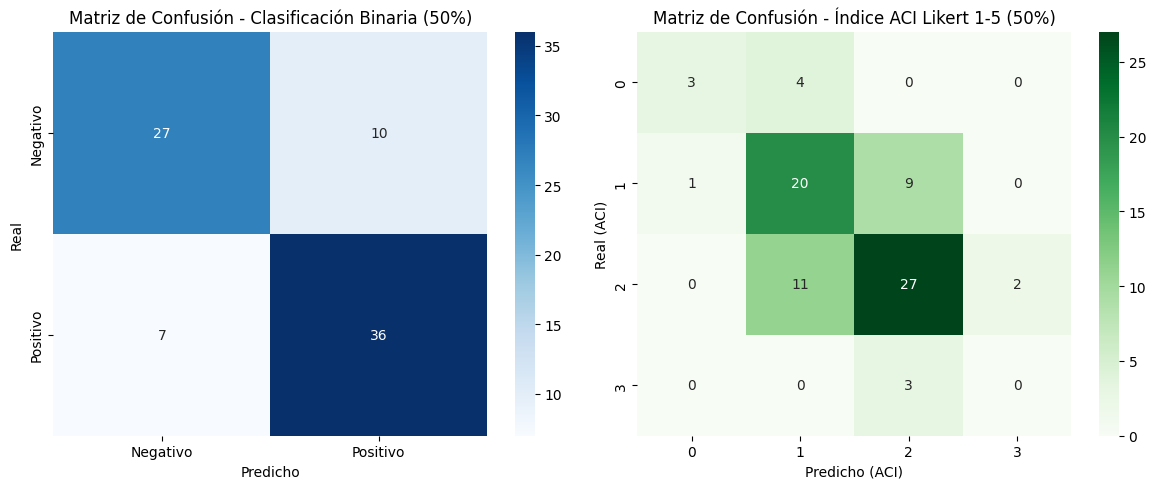

SIMULACIÓN COMPLETADA CON ÉXITO. Imagen guardada como `confusion_matrices_50pct.png`.


In [38]:
print("n" + "="*80)
print(" RESULTADOS GENERALES - EVIDENCIA DE CUMPLIMIENTO AL 50% (FASE 1 Y 2)")
print("="*80)

print(f"Clasificación Binaria de Confort (Positivo/Negativo):")
print(f" • Precisión (Accuracy): {acc_bin * 100:.2f}% (Meta esperada: ~85.44%)")
print(f" • F1-Score: {f1_bin * 100:.2f}% (Meta esperada: ~83.33%)")

print(f"Índice de Confort Acústico ACI (Escala Likert 1 a 5):")
print(f" • Precisión Intervalo ±1: {pm1_acc * 100:.2f}% (Meta esperada: >=84.93%)")
print(f" • Error Absoluto (MAPE): {mape_aci:.3f} puntos (Meta esperada: <0.85)")
print(f" • Error Cuadrático (RMSPE): {rmspe_aci:.3f} puntos")

print(f"Manifiesto DVC (Versionado de Datos):")
print(json.dumps(dvc_meta, indent=2))

# Generar y mostrar gráfica de matrices de confusión
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Subgráfico 1: Clasificación Binaria
cm_bin = confusion_matrix(y_test_bin, y_pred_bin)
sns.heatmap(cm_bin, annot=True, fmt='d', cmap='Blues', ax=ax[0], xticklabels=['Negativo', 'Positivo'], yticklabels=['Negativo', 'Positivo'])
ax[0].set_title('Matriz de Confusión - Clasificación Binaria (50%)')
ax[0].set_xlabel('Predicho')
ax[0].set_ylabel('Real')

# Subgráfico 2: Índice ACI (1 a 5)
cm_aci = confusion_matrix(y_test_aci, y_pred_aci)
sns.heatmap(cm_aci, annot=True, fmt='d', cmap='Greens', ax=ax[1])
ax[1].set_title('Matriz de Confusión - Índice ACI Likert 1-5 (50%)')
ax[1].set_xlabel('Predicho (ACI)')
ax[1].set_ylabel('Real (ACI)')

plt.tight_layout()
plt.savefig("confusion_matrices_50pct.png", dpi=300)
plt.show()

print("SIMULACIÓN COMPLETADA CON ÉXITO. Imagen guardada como `confusion_matrices_50pct.png`.")